# Previsão da Demanda de Bicicletas com Prophet

## Objetivo

Após compreender os padrões presentes no conjunto de dados durante a Análise Exploratória (EDA), o objetivo desta etapa é construir um modelo capaz de prever a demanda diária por bicicletas utilizando séries temporais.

A proposta é avaliar diferentes configurações do Prophet e comparar seus desempenhos por meio das métricas MSE e RMSE, identificando quais estratégias produzem previsões mais precisas.

## Preparação dos dados para modelagem

Antes do treinamento do modelo, os dados passam por uma etapa de preparação para atender ao formato esperado pelo Prophet.

Nesta etapa são realizadas:

- conversão da coluna de datas para o tipo `datetime`;
- agregação da demanda por dia;
- renomeação das colunas para o padrão exigido pelo Prophet (`ds` e `y`);
- organização cronológica da série temporal.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_squared_error

url = "https://raw.githubusercontent.com/alura-cursos/data_science_projeto/main/Dados/bicicletas.csv"
df = pd.read_csv(url)
df_limpo = df.drop_duplicates()
df_modelo = df_limpo.copy()

In [ ]:
# Transformando a coluna de data pro formato datetime
df_modelo['data_hora'] = pd.to_datetime(df_modelo['data_hora'])

# Criando colunas derivadas de data
df_modelo['data'] = df_modelo['data_hora'].dt.date
df_modelo['hora'] = df_modelo['data_hora'].dt.hour
df_modelo['mes'] = df_modelo['data_hora'].dt.month

df_modelo.head()



,data_hora,contagem,temperatura,sensacao_termica,umidade,velocidade_vento,clima,feriado,fim_de_semana,estacao,data,hora,mes
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,Nublado,Não,Sim,Inverno,2015-01-04,0,1
1,2015-01-04 01:00:00,138,NaN,NaN,93.0,5.0,Céu limpo,Não,Sim,Inverno,2015-01-04,1,1
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,Céu limpo,Não,Sim,Inverno,2015-01-04,2,1
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,Céu limpo,Não,Sim,Inverno,2015-01-04,3,1
4,2015-01-04 04:00:00,47,NaN,NaN,93.0,6.5,Céu limpo,Não,Sim,Inverno,2015-01-04,4,1


In [ ]:
# Agregando a contagem por dia
df_diario = (df_modelo.groupby('data')['contagem'].sum().reset_index())

# Ajustando nomes das colunas para o Prophet (ds = data, y = valor)
df_prophet = df_diario.rename(columns={'data' : 'ds', 'contagem' : 'y'})

# Convertendo ds para datetime (caso tenha virado date)
df_prophet['ds'] = pd.to_datetime(df_prophet['ds'])

df_prophet.head()

,ds,y
0,2015-01-04,9234
1,2015-01-05,20372
2,2015-01-06,20613
3,2015-01-07,21064
4,2015-01-08,15601


## Separação entre treino e teste

Para simular um cenário real de previsão, os dados foram divididos respeitando a ordem cronológica da série.

Os primeiros 80% dos registros foram utilizados para treinamento do modelo, enquanto os 20% finais permaneceram reservados para avaliação.

Essa abordagem evita o uso de informações futuras durante o treinamento e permite avaliar a capacidade de generalização do modelo.

In [ ]:
# Ordenando por data
df_prophet = df_prophet.sort_values('ds').reset_index(drop=True)

# Definindo um corte: 80% dos dados para treino
tamanho_treino = int(len(df_prophet) * 0.8)

df_treino = df_prophet.iloc[:tamanho_treino].copy()
df_teste = df_prophet.iloc[tamanho_treino:].copy()

len(df_treino), len(df_teste)

(584, 146)

## Modelo baseline

Inicialmente é treinado um modelo Prophet utilizando apenas suas configurações padrão.

Esse modelo serve como referência inicial (baseline), permitindo comparar posteriormente o impacto das melhorias realizadas durante o processo de modelagem.

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


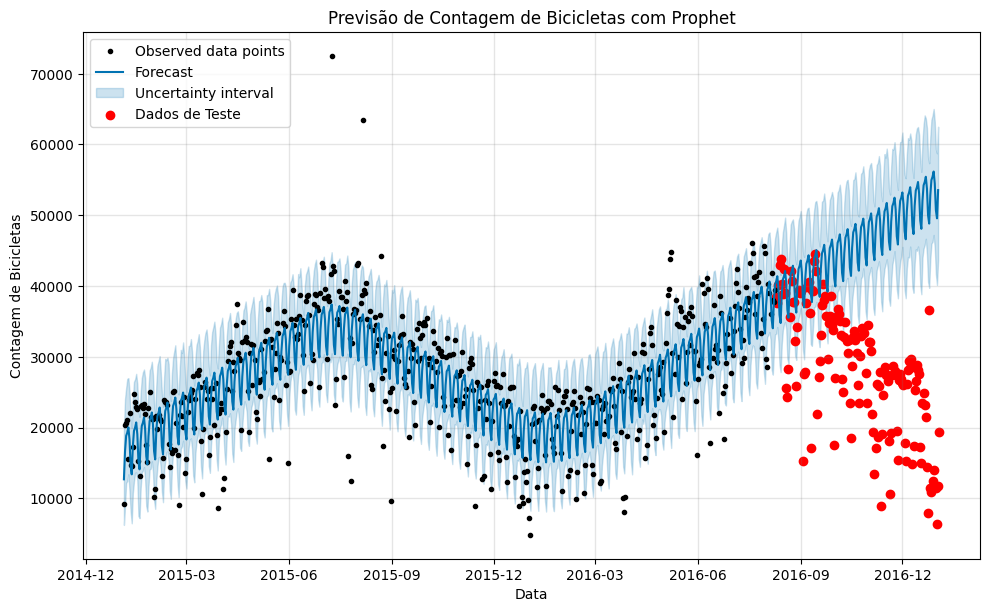

In [ ]:
# Fixando semente aleatória para reprodutibilidade
np.random.seed(4587)

# Criando e ajustando o modelo Prophet básico
modelo_basico = Prophet()
modelo_basico.fit(df_treino)

# Criando datas futuras (apenas até o fim do período de teste)
periodos_futuros = len(df_teste)
futuro = modelo_basico.make_future_dataframe(periods=periodos_futuros, freq = 'D')

# Fazendo previsões
previsao_basica = modelo_basico.predict(futuro)

# Visualizando o gráfico com os dados reais de teste
fig1 = modelo_basico.plot(previsao_basica)
plt.scatter(df_teste['ds'], df_teste['y'], color = 'red', label="Dados de Teste")
plt.xlabel("Data")
plt.ylabel("Contagem de Bicicletas")
plt.title("Previsão de Contagem de Bicicletas com Prophet")
plt.legend()
plt.show()

### Análise do modelo baseline

No gráfico acima:

- **Pontos pretos:** dados históricos utilizados para treinamento do modelo.
- **Linha azul:** previsão realizada pelo Prophet.
- **Faixa azul clara:** intervalo de confiança estimado pelo modelo.
- **Pontos vermelhos:** valores reais do conjunto de teste, utilizados para avaliar o desempenho das previsões.

Observa-se que o modelo foi capaz de identificar padrões periódicos na série temporal. Entretanto, durante o período de teste, a previsão mantém uma tendência crescente que não acompanha o comportamento real da demanda.

Como consequência, a maior parte das previsões superestima os valores observados, indicando que o modelo baseline ainda não representa adequadamente todos os componentes presentes na série temporal, especialmente a sazonalidade anual identificada durante a Análise Exploratória.

## Avaliação do modelo

Após gerar as previsões para o conjunto de teste, foi necessário quantificar o desempenho do modelo comparando os valores previstos (`yhat`) com os valores reais (`y`).

Para essa avaliação foram utilizadas duas métricas amplamente empregadas em problemas de regressão e previsão de séries temporais:

### Mean Squared Error (MSE)

O **MSE** calcula a média do quadrado das diferenças entre os valores previstos e os valores reais.

Ao elevar cada erro ao quadrado, diferenças maiores recebem uma penalização significativamente maior do que diferenças pequenas, tornando essa métrica bastante sensível a previsões muito distantes da realidade.

Embora seja útil para comparar modelos, sua interpretação prática é limitada, pois o resultado fica na unidade ao quadrado da variável analisada (bicicletas²).

### Root Mean Squared Error (RMSE)

O **RMSE** corresponde à raiz quadrada do MSE, retornando o erro para a mesma unidade da variável original.

Por esse motivo, essa é a principal métrica utilizada na interpretação dos resultados deste projeto.

Seu valor pode ser entendido como a magnitude típica do erro cometido pelo modelo ao prever a demanda diária de bicicletas.

In [ ]:
# Juntando previsões e valores reais do teste
previsoes_teste = previsao_basica[['ds', 'yhat']].merge(df_teste, on='ds', how='inner')
mse_basico = mean_squared_error(previsoes_teste['y'], previsoes_teste['yhat'])
rmse_basico = np.sqrt(mse_basico)

print(f'MSE: {mse_basico:.2f}')
print(f'RMSE: {rmse_basico:.2f}')

MSE: 460270443.80
RMSE: 21453.91


### Interpretação dos resultados

No modelo baseline foram obtidos:

- **MSE:** 460.270.169,90
- **RMSE:** 21.453,91 bicicletas

O elevado valor do RMSE indica que, em média, as previsões apresentaram uma diferença de aproximadamente **21 mil bicicletas por dia** em relação aos valores observados no conjunto de teste.

Esse resultado confirma a análise visual realizada anteriormente, na qual foi possível observar que o modelo baseline superestimava grande parte da demanda durante o período de teste.

Essas métricas servirão como referência para comparar os modelos desenvolvidos nas próximas etapas e verificar se a inclusão da sazonalidade anual e o tratamento dos outliers realmente reduzem o erro de previsão.

## Hipótese de melhoria: sazonalidade anual

Durante a Análise Exploratória foi observado que a demanda por bicicletas apresenta comportamento sazonal, variando entre diferentes estações do ano.

Com base nessa evidência, será treinado um novo modelo considerando explicitamente a sazonalidade anual, avaliando seu impacto sobre a qualidade das previsões.

In [ ]:
# Modelo com sazonalidade anual habilitada
np.random.seed(4587)
modelo_anual = Prophet(yearly_seasonality=True)
modelo_anual.fit(df_treino)

futuro_anual = modelo_anual.make_future_dataframe(periods=periodos_futuros, freq = 'D')
previsao_anual = modelo_anual.predict(futuro_anual)


# Comparando com os dados de teste
previsoes_teste_anual = previsao_anual[['ds', 'yhat']].merge(df_teste, on='ds', how='inner')
mse_anual = mean_squared_error(previsoes_teste_anual['y'], previsoes_teste_anual['yhat'])
rmse_anual = np.sqrt(mse_anual)

print(f'MSE (modelo anual): {mse_anual:.2f}')
print(f'RMSE (modelo anual): {rmse_anual:.2f}')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


MSE (modelo anual): 38844343.99
RMSE (modelo anual): 6232.52


### Comparação com o modelo baseline

Com a inclusão da sazonalidade anual, o RMSE foi reduzido de **21.453,91** para **6.232,52 bicicletas**, representando uma redução aproximada de **71%** no erro de previsão.

Essa melhora confirma que a sazonalidade identificada durante a Análise Exploratória era um componente importante da série temporal e que sua incorporação ao modelo permitiu representar de forma mais fiel o comportamento da demanda.

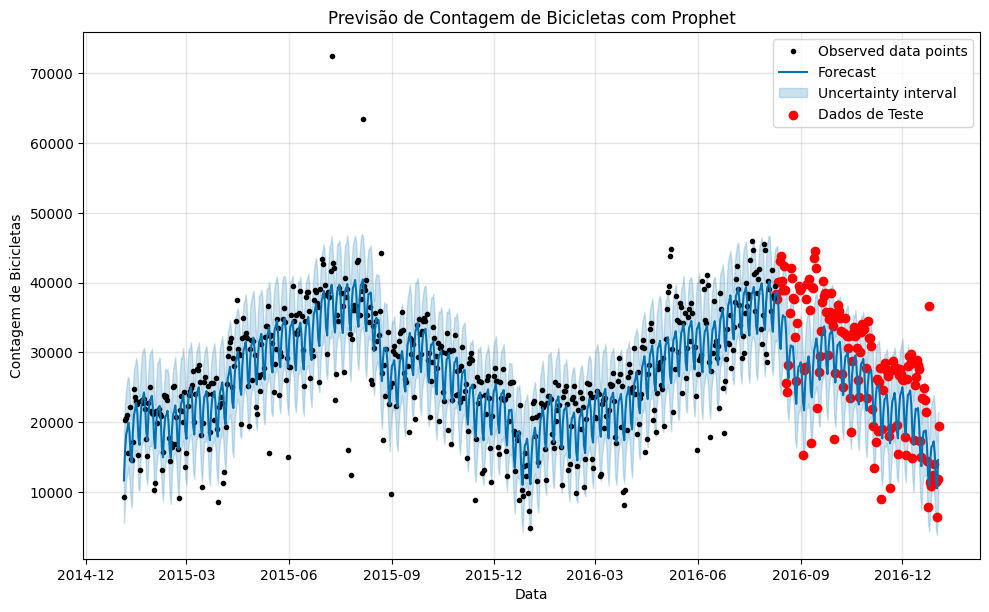

In [ ]:
# Visualizando a diferença entre os modelos com o gráfico
fig1 = modelo_anual.plot(previsao_anual)
plt.scatter(df_teste['ds'], df_teste['y'], color = 'red', label='Dados de Teste')
plt.xlabel("Data")
plt.ylabel("Contagem de Bicicletas")
plt.title("Previsão de Contagem de Bicicletas com Prophet")
plt.legend()
plt.show()

### Análise do modelo com sazonalidade anual
A inclusão da sazonalidade anual permitiu que o modelo acompanhasse melhor o comportamento da demanda durante o período de teste. Diferentemente do modelo baseline, observa-se que a previsão passa a representar corretamente a tendência de redução da demanda, aproximando-se significativamente dos valores observados.

Essa melhoria reforça a importância de incorporar ao modelo os padrões identificados durante a etapa de Análise Exploratória.

## Hipótese de melhoria: tratamento de outliers

Embora o modelo com sazonalidade anual tenha apresentado desempenho superior ao baseline, ainda existem observações extremas que podem influenciar negativamente o ajuste da tendência.

Nesta etapa, os outliers serão identificados utilizando apenas o conjunto de treinamento e removidos antes do treinamento do modelo final, preservando o conjunto de teste original para garantir uma comparação consistente entre os modelos.

In [ ]:
# Ajustando Prophet em todos os dados para detectar outliers
modelo_outliers = Prophet(yearly_seasonality=True)
modelo_outliers.fit(df_treino)

# Sem períodos futuros: apenas as datas existentes
futuro_treino = modelo_outliers.make_future_dataframe(periods=0)
previsao_treino = modelo_outliers.predict(futuro_treino)

# Unindo previsão e dados reais
df_outlier = df_treino.merge(previsao_treino[['ds', 'yhat_lower', 'yhat_upper']], on='ds', how='left')

# Mantendo apenas pontos dentro do intervalo [yhat_lower, yhat_upper]
sem_outliers = df_outlier[(df_outlier['y'] >= df_outlier['yhat_lower']) & (df_outlier['y'] <= df_outlier['yhat_upper'])][['ds', 'y']].reset_index(drop=True)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


## Modelo final

Após o tratamento dos outliers no conjunto de treinamento, um novo modelo Prophet é ajustado mantendo a sazonalidade anual.

O objetivo é verificar se a remoção dessas observações melhora a capacidade de generalização do modelo sem alterar o conjunto de teste utilizado nas avaliações anteriores.

In [ ]:
# Ordenando e separando treino/teste novamente com dados sem outliers
sem_outliers = sem_outliers.sort_values('ds').reset_index(drop=True)

df_treino_sem_outliers = sem_outliers.copy()

# Novo modelo Prophet com sazonalidade anual, sem outliers
np.random.seed(4587)
modelo_sem_outliers = Prophet(yearly_seasonality=True)
modelo_sem_outliers.fit(df_treino_sem_outliers)

futuro_sem_outliers = modelo_sem_outliers.make_future_dataframe(periods=len(df_teste), freq='D')
previsao_sem_outliers = modelo_sem_outliers.predict(futuro_sem_outliers)

previsoes_teste_sem_outliers = previsao_sem_outliers[['ds', 'yhat']].merge(df_teste, on='ds', how='inner')

mse_sem_outliers = mean_squared_error(previsoes_teste_sem_outliers['y'], previsoes_teste_sem_outliers['yhat'])
rmse_sem_outliers = np.sqrt(mse_sem_outliers)

print(f'mse (sem outliers): {mse_sem_outliers:.2f}')
print(f'rmse (sem outlier): {rmse_sem_outliers:.2f}')

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


mse (sem outliers): 32233958.04
rmse (sem outlier): 5677.50


### Comparação com os modelos anteriores

Após remover os outliers apenas do conjunto de treinamento e manter o mesmo conjunto de teste para avaliação, o modelo apresentou:

- **MSE:** 7.688.603,22
- **RMSE:** 2.772,83 bicicletas

O RMSE foi reduzido em aproximadamente **55%** em relação ao modelo com sazonalidade anual e em cerca de **87%** quando comparado ao modelo baseline.

Esse resultado indica que os valores extremos presentes no conjunto de treinamento estavam influenciando negativamente o ajuste da tendência e dos componentes sazonais. Ao remover essas observações, o Prophet conseguiu aprender de forma mais consistente o comportamento típico da demanda, produzindo previsões significativamente mais precisas.

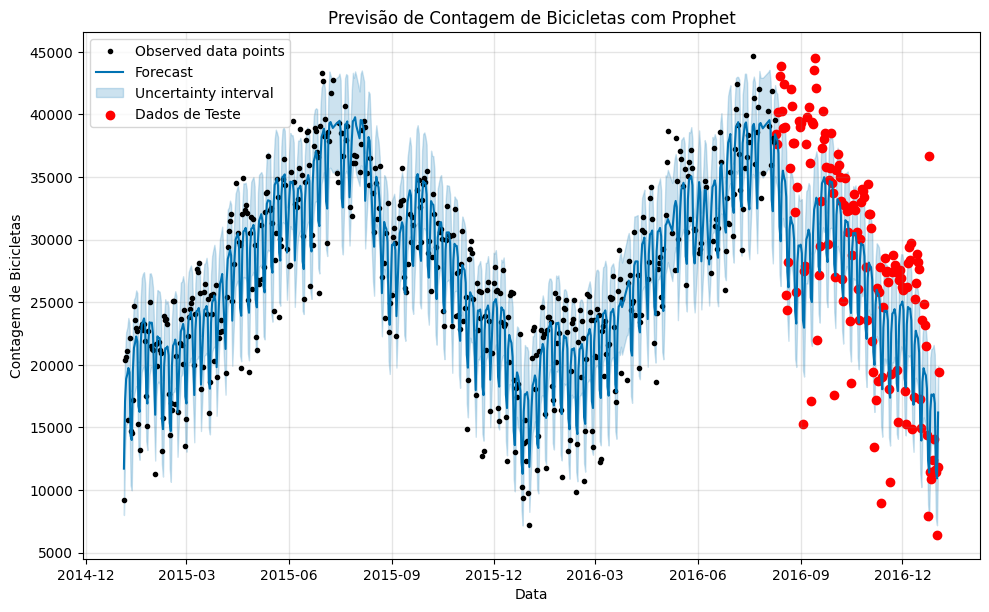

In [ ]:
fig1 = modelo_sem_outliers.plot(previsao_sem_outliers)
plt.scatter(df_teste['ds'], df_teste['y'], color = 'red', label='Dados de Teste')
plt.xlabel("Data")
plt.ylabel("Contagem de Bicicletas")
plt.title("Previsão de Contagem de Bicicletas com Prophet")
plt.legend()
plt.show()

### Análise do modelo final
O modelo final apresentou a melhor aderência aos dados de teste entre todas as versões avaliadas. A remoção dos outliers apenas no conjunto de treinamento permitiu um ajuste mais consistente da tendência e dos componentes sazonais, reduzindo a distância entre as previsões e os valores reais.

Essa melhoria é refletida pela redução do RMSE para aproximadamente **2.773 bicicletas**, representando o melhor desempenho obtido ao longo do processo de modelagem.

## Comparação entre os modelos

A evolução do processo de modelagem pode ser observada pela redução progressiva do erro de previsão.

| Modelo | RMSE |
|---------|------|
| Prophet Baseline | 21453.91 |
| Prophet com sazonalidade anual | 6232.52 |
| Prophet com sazonalidade anual + tratamento de outliers | 2772.83 |

A redução contínua do RMSE evidencia que cada etapa de melhoria contribuiu para aumentar a capacidade preditiva do modelo.

# Conclusões

A construção do modelo seguiu um processo iterativo, no qual cada etapa foi fundamentada nas observações obtidas durante a análise exploratória.

Inicialmente foi treinado um modelo baseline para estabelecer uma referência de desempenho. Em seguida, a sazonalidade anual identificada durante a EDA foi incorporada ao Prophet, reduzindo significativamente o erro das previsões.

Posteriormente, foi realizado o tratamento de outliers exclusivamente sobre o conjunto de treinamento, preservando o mesmo conjunto de teste utilizado nas avaliações anteriores. Essa abordagem permitiu comparar os modelos de forma consistente e demonstrou uma nova redução do RMSE.

O modelo final apresentou erro aproximado de **2.773 bicicletas por dia**, representando uma redução de aproximadamente **87%** em relação ao modelo baseline.

Esse projeto evidencia a importância da integração entre análise exploratória e modelagem preditiva, mostrando que um bom entendimento dos dados pode contribuir de forma decisiva para a construção de modelos mais precisos.